Imports:

In [ ]:
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
from scipy import signal 

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
from sklearn import metrics

Loading data + Q1 tasks

In [ ]:
mat = scipy.io.loadmat('/content/drive/MyDrive/cs/extracellular.mat')

In [ ]:
data1= mat['all_data_with_noise_and_line'][0]

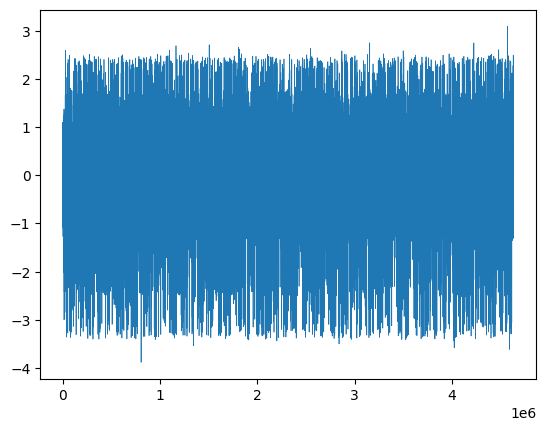

In [ ]:
fig = plt.figure()
plt.plot(data1, linewidth = '0.5')

The first two parts of the spike sorting section were completed using matlab and are not attached here. 
From here on, I have worked on the highpass filtering and peak analysis.

In [ ]:
Wn = 300/1200
b, a = signal.butter(7, Wn,btype='highpass')
hpbw = scipy.signal.filtfilt(b, a, data1) 

In [ ]:
thresh = 5*np.median(np.absolute(hpbw)/0.6745)
thresh

0.2165574093077027

writing an array with 1s wherever the data amplitude passes the threshold:


In [ ]:
binary_ind = []
for ind, sample in enumerate(hpbw):
  if np.absolute(sample) >= thresh:
    # peakval.append(sample)
    #index.append(ind)
    binary_ind.append(1)
  else: 
    binary_ind.append(0)

with a 4ms neighbourhood for each peak duration, here we have formed matrices of the peak values for each of these durations and their coresponding time indexes from the filtered dataset.

In [ ]:
peakval = []
index = []
truepeak = []
truepeakind = []
counter = 0
for i in range(0, len(binary_ind)):
  if binary_ind[i] == 1:
    counter += 1 
    if counter >=5:
     peakval.append([hpbw[i-4], hpbw[i-3], hpbw[i-2], hpbw[i-1], hpbw[i]])
     index.append([i-4, i-3, i-2, i-1, i])
     counter = 0
  

In [ ]:
#calculating the difference of each two consequtive point and then locating peaks by
#the difference of signs between each two gradients 
#diff = np.gradient(peakloc)
#fin_peaks = []
#fin_peaks_ind =[]
#for sample in peakloc:
#  if(diff[i-1] * diff[i]) < 0:  #meaning that oneside is increasing in value and one is decreasing
#    fin_peaks.append(i)
  


In [ ]:
len(peakval)

1089

In [ ]:
#as it can be seen here, we now have a 2d matrix where each row is a waveform
wf = np.vstack(peakval)
wf.shape

(1089, 5)

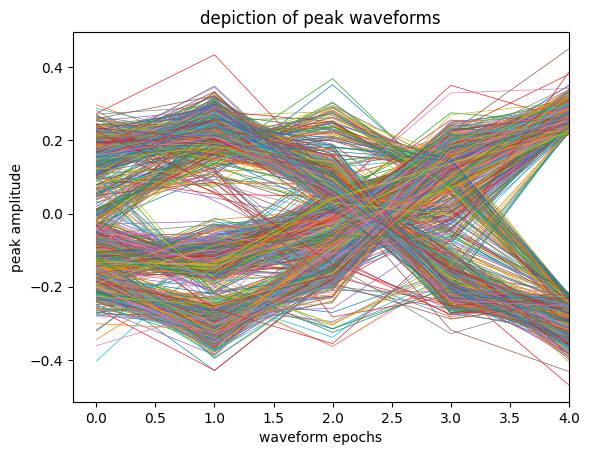

In [ ]:
plt.figure()
for i in range(len(wf)):
    plt.plot(wf[i], linewidth = 0.5)
    plt.xlabel("waveform epochs")
    plt.ylabel("peak amplitude")
    plt.title("depiction of peak waveforms")
    plt.xlim(right = 4)
plt.show()

Applying a PCA for feature extraction

In [ ]:
#wff = np.flipud(wf)
#wff.shape

(1660, 5)

In [ ]:
pca = PCA(n_components = 3)
pca_features = pca.fit_transform(wf)
 
print('Shape before PCA: ', wf.shape)
print('Shape after PCA: ', pca_features.shape)
 


Shape before PCA:  (1089, 5)
Shape after PCA:  (1089, 3)


In [ ]:
pca.explained_variance_

array([0.17318097, 0.01341077, 0.00402515])

In this part we attempt to cluster the spikes with KMeans clustering

In [ ]:
#Kmeans Clustering + annotating on the centeroids of clusters and their labels
kmeans = KMeans(n_clusters = 3).fit(pca_features)
centers = np.array(kmeans.cluster_centers_)
label = kmeans.labels_


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [ ]:
label

array([0, 1, 1, ..., 0, 0, 0], dtype=int32)

In [ ]:
#uniq = np.unique(label)
#uniq

array([0, 1, 2], dtype=int32)

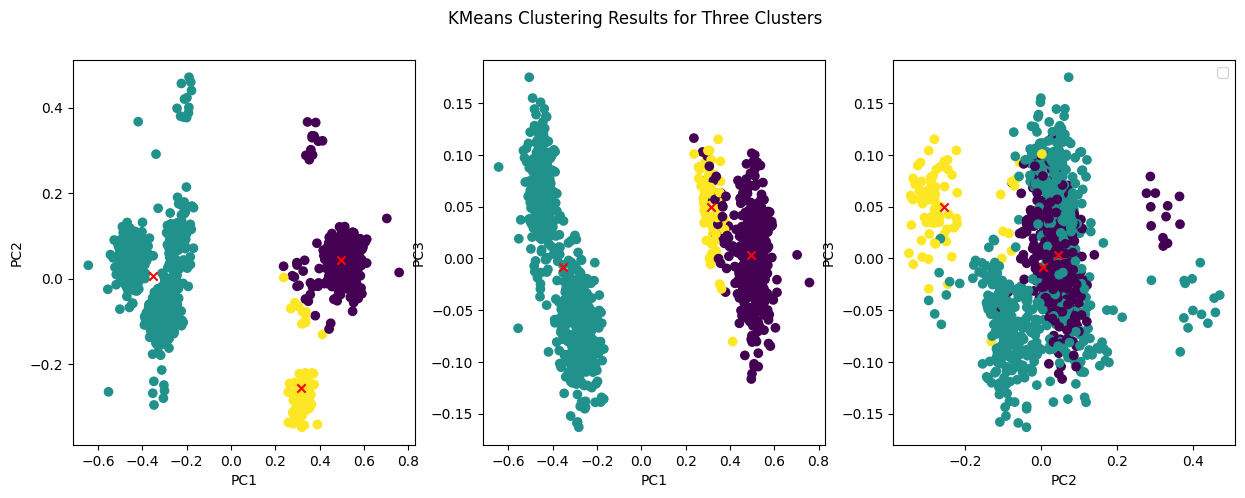

In [ ]:
#Plotting the clusters with the respective centroid
fig, ax = plt.subplots(1,3, figsize=(15,5))
colors = ['red', 'green', 'blue']
#uniq = np.unique(label)
#for i in uniq:
ax[0].scatter(pca_features[: , 0] , pca_features[: , 1] , c = label)
ax[0].scatter(centers[:,0], centers[:,1], marker="x", color='red')
ax[1].scatter(pca_features[: , 0] , pca_features[: , 2] , c = label)
ax[1].scatter(centers[:,0], centers[:,2], marker="x", color='red')
ax[2].scatter(pca_features[: , 1] , pca_features[: , 2] , c = label)
ax[2].scatter(centers[:,1], centers[:,2], marker="x", color='red')
#This is done to find the centroid for each clusters.
fig.suptitle(f'KMeans Clustering Results for Three Clusters')
plt.legend()
ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC3')
ax[2].set_xlabel('PC2')
ax[2].set_ylabel('PC3')
plt.show()
#

Here we employ the elbow method to find the best K for the KMeans algorithm

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:8

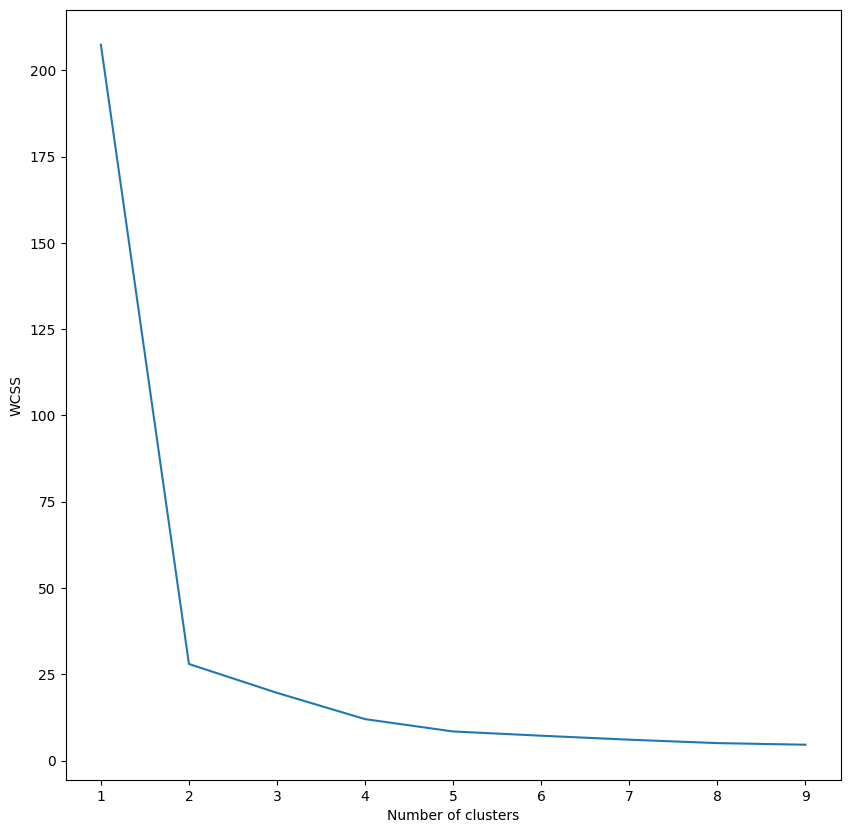

In [ ]:
wcss = []
for i in range(1,10):
   model = KMeans(n_clusters = i, init = "k-means++")
   model.fit(pca_features)
   wcss.append(model.inertia_)
plt.figure(figsize=(10,10))
plt.plot(range(1,10), wcss)
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


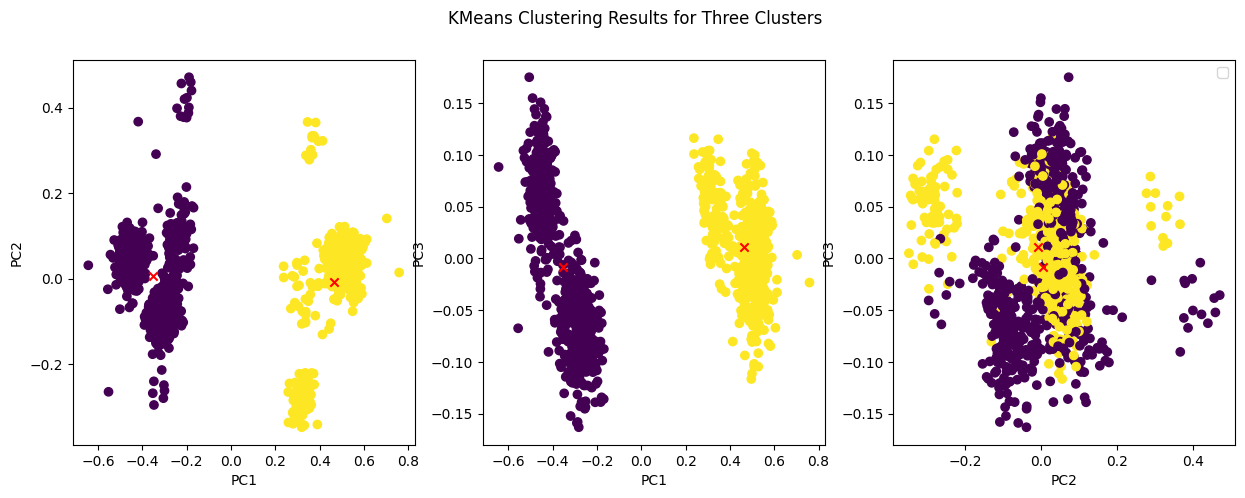

In [ ]:
##repeating the previous plots with the yielded K
##K = 4
 
kmeans2 = KMeans(n_clusters = 2).fit(pca_features)
centers2 = np.array(kmeans2.cluster_centers_)
label2 = kmeans2.labels_


fig, ax = plt.subplots(1,3, figsize=(15,5))
ax[0].scatter(pca_features[: , 0] , pca_features[: , 1] , c = label2)
ax[0].scatter(centers2[:,0], centers2[:,1], marker="x", color='red')
ax[1].scatter(pca_features[: , 0] , pca_features[: , 2] , c = label2)
ax[1].scatter(centers2[:,0], centers2[:,2], marker="x", color='red')
ax[2].scatter(pca_features[: , 1] , pca_features[: , 2] , c = label2)
ax[2].scatter(centers2[:,1], centers2[:,2], marker="x", color='red')
#This is done to find the centroid for each clusters.
fig.suptitle(f'KMeans Clustering Results for Three Clusters')
plt.legend()
ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC3')
ax[2].set_xlabel('PC2')
ax[2].set_ylabel('PC3')
plt.show()
#


# **From here on, we will be loading the Spikes.mat dataset and analyzing it as per instructed**

In [ ]:
mat = scipy.io.loadmat('/content/drive/MyDrive/cs/spikes.mat')
data2= mat['SpikeInds'][0]

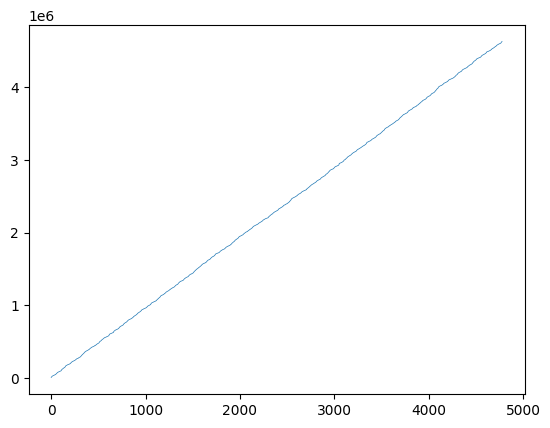

In [ ]:
fig = plt.figure()
plt.plot(data2, linewidth = '0.5')

In [ ]:
data2.shape

(4779,)

(array([490., 469., 492., 467., 491., 491., 449., 481., 465., 484.]),
 array([2.7190000e+03, 4.6563550e+05, 9.2855200e+05, 1.3914685e+06,
        1.8543850e+06, 2.3173015e+06, 2.7802180e+06, 3.2431345e+06,
        3.7060510e+06, 4.1689675e+06, 4.6318840e+06]),
 <BarContainer object of 10 artists>)

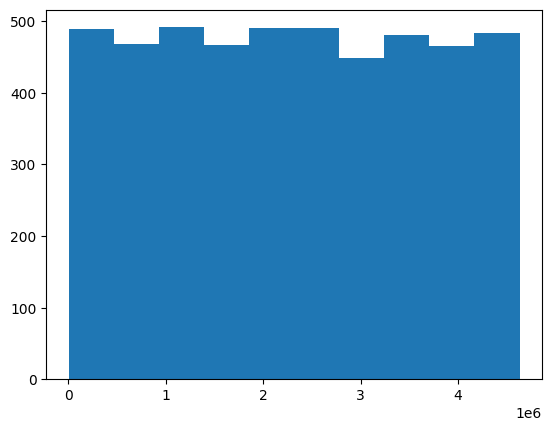

In [ ]:
plt.hist(data2)

Here we compare the detected spikes of the previous part to the real data of spikes.mat to analyze the percision of our spike detection. 

In [ ]:
index = np.array(index)


In [ ]:
true = 0 
for sample in data2:
  if sample in index:
    true += 1

In [ ]:
percision = (true/len(data2))
percision

0.6633186859175559

In [ ]:
true

317

In [ ]:
confusion_matrix = metrics.confusion_matrix(data2, index)

ValueError: ignored